## **Trabajo Práctico Final: Airbnb Price - Pipeline**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Ciencia de Datos - Curso I5521__
____

- Nombre: Facundo
- Apellido: Del Bono

# Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.decomposition import PCA

import lightgbm as lgb

# Dataset

In [2]:
df = pd.read_csv('airbnb_us.csv')

df.head()

,id,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds,price
0,13418779,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,SF,...,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0,750.0
1,3808709,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,DC,...,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0,115.0
2,12422935,Apartment,Private room,"{TV,""Wireless Internet"",Heating,""Smoke detecto...",2,1.0,Real Bed,strict,True,SF,...,-122.429526,Comfort Suite San Francisco,Noe Valley,3,100.0,https://a0.muscache.com/im/pictures/82509143-4...,94131,1.0,1.0,85.0
3,180792,House,Private room,"{TV,""Cable TV"",""Wireless Internet"",""Pets live ...",2,1.0,Real Bed,moderate,True,SF,...,-122.501095,Cozy Garden Studio - Private Entry,Richmond District,159,99.0,https://a0.muscache.com/im/pictures/0ed6c128-7...,94121,1.0,1.0,120.0
4,2658946,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",6,1.5,Real Bed,strict,True,DC,...,-77.031189,Charming 2 bdrm in trendy U/14th streets w/par...,U Street Corridor,13,89.0,NaN,20009,2.0,3.0,200.0


In [3]:
print(df.shape)

(19309, 29)


# Limpieza

## Columnas que no vamos a usar

In [4]:
df = df.drop(columns=['id', 'thumbnail_url', 'name', 'zipcode'])

## Tipos de datos

In [5]:
df['host_response_rate'] = df['host_response_rate'].str.replace('%', '')
df['host_response_rate'] = df['host_response_rate'].astype(float)

In [6]:
df['host_has_profile_pic'] = df['host_has_profile_pic'].map({'t': 1, 'f': 0})
df['host_identity_verified'] = df['host_identity_verified'].map({'t': 1, 'f': 0})
df['instant_bookable'] = df['instant_bookable'].map({'t': 1, 'f': 0})

df['cleaning_fee'] = df['cleaning_fee'].astype(int)

In [7]:
df['host_since'] = pd.to_datetime(df['host_since'])
df['first_review'] = pd.to_datetime(df['first_review'])
df['last_review'] = pd.to_datetime(df['last_review'])

## Nuevas variables

In [8]:
fecha_ref = df['last_review'].max()
print(fecha_ref)

2017-10-05 00:00:00


In [9]:
df['host_antiguedad'] = (fecha_ref - df['host_since']).dt.days / 365

In [10]:
df['n_amenities'] = df['amenities'].str.count(',') + 1

df.loc[df['amenities'] == '{}', 'n_amenities'] = 0

In [11]:
lista_amenities = df['amenities'].str.replace('{', '').str.replace('}', '').str.replace('"', '').str.split(',')

df['am_tv'] = lista_amenities.apply(lambda x: 'TV' in x).astype(int)
df['am_kitchen'] = lista_amenities.apply(lambda x: 'Kitchen' in x).astype(int)
df['am_fireplace'] = lista_amenities.apply(lambda x: 'Indoor fireplace' in x).astype(int)
df['am_gym'] = lista_amenities.apply(lambda x: 'Gym' in x).astype(int)
df['am_pool'] = lista_amenities.apply(lambda x: 'Pool' in x).astype(int)
df['am_doorman'] = lista_amenities.apply(lambda x: 'Doorman' in x).astype(int)

In [12]:
df['tiene_reviews'] = (df['number_of_reviews'] > 0).astype(int)

In [13]:
df['largo_descripcion'] = df['description'].str.len()

print(df['largo_descripcion'].describe())

count    19309.000000
mean       798.066083
std        303.436978
min          1.000000
25%        547.000000
50%       1000.000000
75%       1000.000000
max       1000.000000
Name: largo_descripcion, dtype: float64


In [14]:
df = df.drop(columns=['amenities', 'host_since', 'first_review', 'last_review', 'description'])

## Completar nulos

In [15]:
df = df.dropna(subset=['bathrooms', 'bedrooms', 'beds', 'host_has_profile_pic'])

In [16]:
df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].median())
df['review_scores_rating'] = df['review_scores_rating'].fillna(df['review_scores_rating'].median())

df['neighbourhood'] = df['neighbourhood'].fillna('Desconocido')

In [17]:
print(df.isnull().sum().sum())

0


In [18]:
print(df.shape)

(19243, 30)


## Logaritmo del precio

In [19]:
df['log_price'] = np.log(df['price'])

# Variables X e y

In [20]:
y = df['log_price']

X = df.drop(columns=['price', 'log_price', 'neighbourhood'])

print(X.shape)
print(y.shape)

(19243, 28)
(19243,)


# Variables categóricas

In [21]:
conteo = X['property_type'].value_counts()
tipos_raros = conteo[conteo < 30].index
X.loc[X['property_type'].isin(tipos_raros), 'property_type'] = 'Other'

X['property_type'].value_counts()

property_type
Apartment          11468
House               4789
Condominium         1566
Townhouse            500
Other                242
Loft                 205
Bed & Breakfast      134
Guest suite           65
In-law                64
Guesthouse            54
Boutique hotel        47
Dorm                  46
Timeshare             33
Boat                  30
Name: count, dtype: int64

In [22]:
columnas_categoricas = ['property_type', 'room_type', 'bed_type', 'cancellation_policy', 'city']
columnas_numericas = X.drop(columns=columnas_categoricas).columns

print(len(columnas_numericas))
print(len(columnas_categoricas))

23
5


# Train y test

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)

(15394, 28)
(3849, 28)


# Preprocesamiento: Pipeline y ColumnTransformer

In [24]:
transformador_cat = Pipeline([('dummies', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
                              ('escalado', StandardScaler())])

preprocesador = ColumnTransformer([
    ('num', StandardScaler(), columnas_numericas),
    ('cat', transformador_cat, columnas_categoricas)],
    verbose_feature_names_out=False)

# Métricas

In [25]:
def evaluar(nombre, modelo, X_tr, X_te):
    pred_train = modelo.predict(X_tr)
    pred_test = modelo.predict(X_te)

    r2_train = r2_score(y_train, pred_train)
    r2_test = r2_score(y_test, pred_test)

    precio_real = np.exp(y_test)
    precio_pred = np.exp(pred_test)

    rmse = np.sqrt(mean_squared_error(precio_real, precio_pred))
    mae = mean_absolute_error(precio_real, precio_pred)

    return {'Modelo': nombre, 'R2 train': r2_train, 'R2 test': r2_test, 'RMSE (USD)': rmse, 'MAE (USD)': mae}

resultados = []

# Baseline

In [26]:
train_base = X_train[['city', 'room_type']].copy()
train_base['log_price'] = y_train
medianas = train_base.groupby(['city', 'room_type'])['log_price'].median()
print(medianas)

city     room_type      
Boston   Entire home/apt    5.192957
         Private room       4.310777
         Shared room        4.196947
Chicago  Entire home/apt    4.882802
         Private room       4.094345
         Shared room        3.433987
DC       Entire home/apt    5.010635
         Private room       4.369448
         Shared room        3.806662
SF       Entire home/apt    5.416100
         Private room       4.605170
         Shared room        4.248495
Name: log_price, dtype: float64


In [27]:
pred_base_train = X_train.set_index(['city', 'room_type']).index.map(medianas)
pred_base_test = X_test.set_index(['city', 'room_type']).index.map(medianas)

res_base = {'Modelo': 'Baseline (mediana ciudad x tipo)',
            'R2 train': r2_score(y_train, pred_base_train),
            'R2 test': r2_score(y_test, pred_base_test),
            'RMSE (USD)': np.sqrt(mean_squared_error(np.exp(y_test), np.exp(pred_base_test))),
            'MAE (USD)': mean_absolute_error(np.exp(y_test), np.exp(pred_base_test))}
resultados.append(res_base)
pd.DataFrame([res_base]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Baseline (mediana ciudad x tipo),0.341,0.347,200.564,93.502


# Regresión lineal

In [28]:
lr = Pipeline([('prep', preprocesador), ('modelo', LinearRegression())])
lr.fit(X_train, y_train)

res_lr = evaluar('Regresión lineal', lr, X_train, X_test)
resultados.append(res_lr)
pd.DataFrame([res_lr]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Regresión lineal,0.579,0.577,164.42,78.073


# Ridge

In [29]:
param_ridge = {'modelo__alpha': [0.01, 0.1, 1, 10, 100, 1000]}

ridge = Pipeline([('prep', preprocesador), ('modelo', Ridge())])
grid_ridge = GridSearchCV(ridge, param_ridge, cv=5, scoring='r2')
grid_ridge.fit(X_train, y_train)

print(grid_ridge.best_params_)
print(grid_ridge.best_score_)

{'modelo__alpha': 0.01}
0.5749244811055926


In [30]:
res_ridge = evaluar('Ridge', grid_ridge.best_estimator_, X_train, X_test)
resultados.append(res_ridge)
pd.DataFrame([res_ridge]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Ridge,0.579,0.577,164.33,78.096


# Árbol de decisión

In [31]:
param_arbol = {'modelo__max_depth': [5, 10, 15, 20],
               'modelo__min_samples_leaf': [10, 20, 50, 100]}

arbol = Pipeline([('prep', preprocesador), ('modelo', DecisionTreeRegressor(random_state=42))])
grid_arbol = GridSearchCV(arbol, param_arbol, cv=5, scoring='r2')
grid_arbol.fit(X_train, y_train)

print(grid_arbol.best_params_)
print(grid_arbol.best_score_)

{'modelo__max_depth': 20, 'modelo__min_samples_leaf': 50}
0.5879565695167178


In [32]:
res_arbol = evaluar('Árbol de decisión', grid_arbol.best_estimator_, X_train, X_test)
resultados.append(res_arbol)
pd.DataFrame([res_arbol]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Árbol de decisión,0.643,0.59,158.004,76.177


# Random Forest

In [33]:
param_rf = {'modelo__max_depth': [10, 20, None],
            'modelo__min_samples_leaf': [1, 5]}

rf = Pipeline([('prep', preprocesador),
               ('modelo', RandomForestRegressor(n_estimators=100, max_features=0.33, random_state=42, n_jobs=-1))])
grid_rf = GridSearchCV(rf, param_rf, cv=3, scoring='r2')
grid_rf.fit(X_train, y_train)

print(grid_rf.best_params_)
print(grid_rf.best_score_)

{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1}
0.6582058881479383


In [34]:
res_rf = evaluar('Random Forest', grid_rf.best_estimator_, X_train, X_test)
resultados.append(res_rf)
pd.DataFrame([res_rf]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Random Forest,0.953,0.66,150.617,68.92


# LightGBM

In [35]:
param_lgbm = {'modelo__n_estimators': [300, 600, 1000],
              'modelo__learning_rate': [0.03, 0.05, 0.1],
              'modelo__num_leaves': [15, 31, 63],
              'modelo__min_child_samples': [10, 20, 50]}

lgbm = Pipeline([('prep', preprocesador),
                 ('modelo', lgb.LGBMRegressor(random_state=42, verbose=-1))])

random_lgbm = RandomizedSearchCV(lgbm, param_lgbm, n_iter=15, cv=3, scoring='r2', random_state=42)
random_lgbm.fit(X_train, y_train)

print(random_lgbm.best_params_)
print(random_lgbm.best_score_)

{'modelo__num_leaves': 31, 'modelo__n_estimators': 600, 'modelo__min_child_samples': 10, 'modelo__learning_rate': 0.03}
0.6721032820937944


In [36]:
res_lgbm = evaluar('LightGBM', random_lgbm.best_estimator_, X_train, X_test)
resultados.append(res_lgbm)
pd.DataFrame([res_lgbm]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,LightGBM,0.791,0.668,148.394,68.477


# PCA

In [37]:
X_train_prep = preprocesador.fit_transform(X_train)

pca_completo = PCA()
pca_completo.fit(X_train_prep)

varianza = pca_completo.explained_variance_ratio_
varianza_acum = np.cumsum(varianza)

In [38]:
print('80%:', (varianza_acum < 0.80).sum() + 1)
print('90%:', (varianza_acum < 0.90).sum() + 1)
print('95%:', (varianza_acum < 0.95).sum() + 1)

print(varianza[0:5].round(3))

80%: 30
90%: 37
95%: 41
[0.078 0.062 0.049 0.046 0.038]


In [39]:
n_componentes = (varianza_acum < 0.90).sum() + 1
print(n_componentes)

37


# Modelos con PCA

## Regresión lineal + PCA

In [40]:
lr_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)), ('modelo', LinearRegression())])
lr_pca.fit(X_train, y_train)

res_lr_pca = evaluar('Regresión lineal + PCA', lr_pca, X_train, X_test)
resultados.append(res_lr_pca)
pd.DataFrame([res_lr_pca]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Regresión lineal + PCA,0.559,0.561,172.998,79.927


## Ridge + PCA

In [41]:
ridge_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)), ('modelo', Ridge())])
grid_ridge_pca = GridSearchCV(ridge_pca, param_ridge, cv=5, scoring='r2')
grid_ridge_pca.fit(X_train, y_train)
print(grid_ridge_pca.best_params_)

res_ridge_pca = evaluar('Ridge + PCA', grid_ridge_pca.best_estimator_, X_train, X_test)
resultados.append(res_ridge_pca)
pd.DataFrame([res_ridge_pca]).round(3)

{'modelo__alpha': 100}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Ridge + PCA,0.559,0.561,172.943,79.908


## Árbol de decisión + PCA

In [42]:
arbol_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)), ('modelo', DecisionTreeRegressor(random_state=42))])
grid_arbol_pca = GridSearchCV(arbol_pca, param_arbol, cv=5, scoring='r2')
grid_arbol_pca.fit(X_train, y_train)
print(grid_arbol_pca.best_params_)

res_arbol_pca = evaluar('Árbol de decisión + PCA', grid_arbol_pca.best_estimator_, X_train, X_test)
resultados.append(res_arbol_pca)
pd.DataFrame([res_arbol_pca]).round(3)

{'modelo__max_depth': 10, 'modelo__min_samples_leaf': 50}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Árbol de decisión + PCA,0.593,0.504,165.856,82.648


## Random Forest + PCA

In [43]:
rf_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)),
                   ('modelo', RandomForestRegressor(n_estimators=100, max_features=0.33, random_state=42, n_jobs=-1))])
grid_rf_pca = GridSearchCV(rf_pca, param_rf, cv=3, scoring='r2')
grid_rf_pca.fit(X_train, y_train)
print(grid_rf_pca.best_params_)

res_rf_pca = evaluar('Random Forest + PCA', grid_rf_pca.best_estimator_, X_train, X_test)
resultados.append(res_rf_pca)
pd.DataFrame([res_rf_pca]).round(3)

{'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Random Forest + PCA,0.838,0.599,159.434,75.173


## LightGBM + PCA

In [44]:
lgbm_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)),
                     ('modelo', lgb.LGBMRegressor(random_state=42, verbose=-1))])
random_lgbm_pca = RandomizedSearchCV(lgbm_pca, param_lgbm, n_iter=15, cv=3, scoring='r2', random_state=42)
random_lgbm_pca.fit(X_train, y_train)
print(random_lgbm_pca.best_params_)

res_lgbm_pca = evaluar('LightGBM + PCA', random_lgbm_pca.best_estimator_, X_train, X_test)
resultados.append(res_lgbm_pca)
pd.DataFrame([res_lgbm_pca]).round(3)

{'modelo__num_leaves': 15, 'modelo__n_estimators': 600, 'modelo__min_child_samples': 20, 'modelo__learning_rate': 0.03}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,LightGBM + PCA,0.708,0.599,156.926,75.558


# Comparación final

In [45]:
tabla_final = pd.DataFrame(resultados).round(3)
tabla_final

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Baseline (mediana ciudad x tipo),0.341,0.347,200.564,93.502
1,Regresión lineal,0.579,0.577,164.420,78.073
2,Ridge,0.579,0.577,164.330,78.096
3,Árbol de decisión,0.643,0.590,158.004,76.177
4,Random Forest,0.953,0.660,150.617,68.920
5,LightGBM,0.791,0.668,148.394,68.477
6,Regresión lineal + PCA,0.559,0.561,172.998,79.927
7,Ridge + PCA,0.559,0.561,172.943,79.908
8,Árbol de decisión + PCA,0.593,0.504,165.856,82.648
9,Random Forest + PCA,0.838,0.599,159.434,75.173


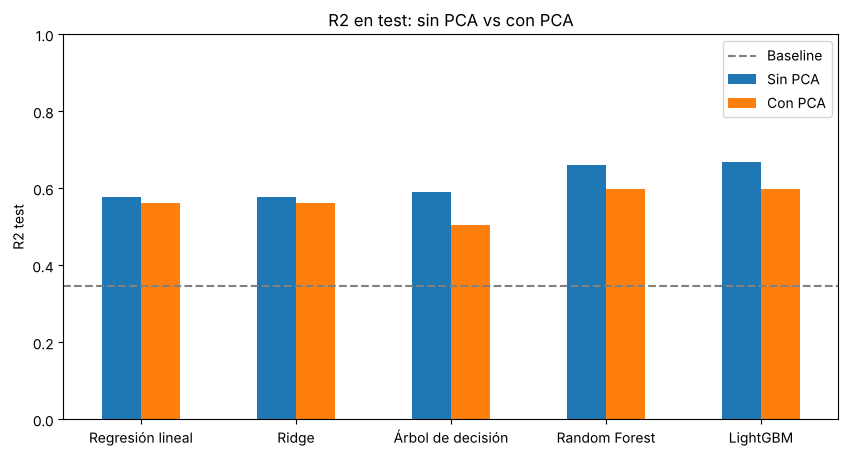

In [46]:
comparacion = pd.DataFrame({'Sin PCA': tabla_final['R2 test'][1:6].values,
                            'Con PCA': tabla_final['R2 test'][6:11].values},
                           index=['Regresión lineal', 'Ridge', 'Árbol de decisión', 'Random Forest', 'LightGBM'])

comparacion.plot(kind='bar', figsize=(10,5))
plt.axhline(tabla_final['R2 test'][0], color='gray', linestyle='--', label='Baseline')
plt.title('R2 en test: sin PCA vs con PCA')
plt.ylabel('R2 test')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend()
plt.show()